In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install scikit-plot


In [ ]:
pip install pydub

In [ ]:
pip install python-firebase                                 #dont use this, instead use below github library, that library works and this one doesnt

  Created wheel for python-firebase: filename=python_firebase-1.2-cp37-none-any.whl size=11533 sha256=d5ab06848c26318bf9b8a0f731e468412079a95a633d367544aec2c15b2cdcc6
  Stored in directory: /root/.cache/pip/wheels/ba/40/ca/e41a25d7abb787092e837cb0f91f33b04b1a8fd9d17c2d33a6
Successfully built python-firebase


In [ ]:
pip install git+https://github.com/ozgur/python-firebase        #this works instead of normal python-firebase library install

  Cloning https://github.com/ozgur/python-firebase to /tmp/pip-req-build-swfzsrl3
  Running command git clone -q https://github.com/ozgur/python-firebase /tmp/pip-req-build-swfzsrl3
  Created wheel for python-firebase: filename=python_firebase-1.2.1-cp37-none-any.whl size=12533 sha256=b68289e9d3b089388ee0f2245d2b075295df3adc2cb7d39a81d17effac0d2572
  Stored in directory: /tmp/pip-ephem-wheel-cache-05tmp8le/wheels/ef/40/57/99d925b3495995b9930edfb8f4033cb9a8dbf838848d5a65ba
Successfully built python-firebase


In [ ]:
pip install requests

In [ ]:
pip install firebase-admin

In [ ]:
pip install sklearn

In [ ]:
import librosa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import os
from PIL import Image
import pathlib
import csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import keras
from keras import layers
from keras import layers
import keras
from keras.models import Sequential
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
import pydub
from pydub import AudioSegment
from sklearn.metrics import confusion_matrix as cm
from sklearn.metrics import roc_auc_score as aucroc
from sklearn.metrics import roc_curve as rocc
import scikitplot as skplt
from sklearn.metrics import f1_score as f1
from math import sqrt
from firebase import firebase
firebase=firebase.FirebaseApplication('https://<your-firebase-link-to-send-data-to>', None)

In [ ]:
header = 'chroma_stft rmse spectral_centroid spectral_bandwidth rolloff zero_crossing_rate'
for i in range(1, 21):
    header += f' mfcc{i}'
header += ' crying?'
header = header.split()

file = open('dataset.csv', 'w', newline='')
with file:
    writer = csv.writer(file)
    writer.writerow(header)
guess = 'crying notcrying'.split()
for g in guess:
    for filename in os.listdir(f'./drive/My Drive/<your-dataset-location>/{g}'):
        audioname = f'./drive/My Drive/<your-dataset-location>/{g}/{filename}'
        y, sr = librosa.load(audioname, mono=True, duration=5)
        rmse = librosa.feature.rms(y=y)
        chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
        spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
        spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y)
        mfcc = librosa.feature.mfcc(y=y, sr=sr)
        to_append = f'{np.mean(chroma_stft)} {np.mean(rmse)} {np.mean(spec_cent)} {np.mean(spec_bw)} {np.mean(rolloff)} {np.mean(zcr)}'
        for e in mfcc:
            to_append += f' {np.mean(e)}'
        if g == 'crying':
          a=1
        else:
          a=0
        to_append += f' {a}'
        file = open('dataset.csv', 'a', newline='')
        with file:
            writer = csv.writer(file)
            writer.writerow(to_append.split())

In [ ]:
df = pd.read_csv('dataset.csv')           #either this one or the code below it, because this one reads created features dataset file, while below one reads features dataset file from google drive
df.head()

,chroma_stft,rmse,spectral_centroid,spectral_bandwidth,rolloff,zero_crossing_rate,mfcc1,mfcc2,mfcc3,mfcc4,mfcc5,mfcc6,mfcc7,mfcc8,mfcc9,mfcc10,mfcc11,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19,mfcc20,crying?
0,0.225691,0.090768,1725.935490,928.493632,2786.406453,0.159055,-327.677307,132.783386,-91.839615,-7.439297,8.334653,-56.758183,-1.752443,12.278805,-34.896519,-8.329695,9.827935,-5.286853,10.230895,6.478723,-12.261278,-4.435557,-6.802001,-11.261151,-1.351774,-5.508152,1
1,0.248956,0.198510,1236.742380,738.213030,2102.228800,0.084461,-266.342041,130.098419,-64.027847,-32.130341,5.809711,-33.962479,-20.708084,4.806234,-12.043502,-13.655785,-5.383581,-10.640455,-7.571898,-2.331328,1.148056,12.219123,14.053530,6.468319,3.401286,-2.716210,1
2,0.320830,0.073203,1256.993618,810.519903,2136.372884,0.097593,-330.473175,158.760025,-71.102249,-7.219061,14.671421,-38.684940,-4.904061,4.646159,-13.265660,6.505092,-6.560058,-19.567343,0.905371,-8.766528,-12.382949,6.625433,-2.144613,-1.713878,10.838818,-4.857569,1
3,0.302398,0.053724,1097.375920,843.306098,2083.536784,0.073654,-361.638519,127.335640,-31.089331,3.324579,10.170507,-35.319706,-9.989314,9.413016,-6.661982,-1.571426,-1.965317,-8.855414,-4.439231,-11.310555,-10.731737,2.845137,0.622317,2.182530,9.883195,-1.467275,1
4,0.274019,0.164837,995.095245,770.297869,1785.411580,0.069273,-347.019531,116.264565,-30.145157,-6.010990,1.343266,-32.674175,-11.814300,-2.443383,-17.264055,-8.622743,-7.267488,-7.376657,5.904398,5.001906,9.433987,17.565327,-2.458547,-12.820093,-2.307046,-7.396687,1


In [ ]:
df = pd.read_csv(f'./drive/My Drive/<your-features-csv-location>.csv')            #read csv file from google drive which already has all features
df.head()

,chroma_stft,rmse,spectral_centroid,spectral_bandwidth,rolloff,zero_crossing_rate,mfcc1,mfcc2,mfcc3,mfcc4,mfcc5,mfcc6,mfcc7,mfcc8,mfcc9,mfcc10,mfcc11,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19,mfcc20,crying?
0,0.225691,0.090768,1725.935490,928.493632,2786.406453,0.159055,-327.677307,132.783386,-91.839615,-7.439297,8.334653,-56.758183,-1.752443,12.278805,-34.896519,-8.329695,9.827935,-5.286853,10.230895,6.478723,-12.261278,-4.435557,-6.802001,-11.261151,-1.351774,-5.508152,1
1,0.248956,0.198510,1236.742380,738.213030,2102.228800,0.084461,-266.342041,130.098419,-64.027847,-32.130341,5.809711,-33.962479,-20.708084,4.806234,-12.043502,-13.655785,-5.383581,-10.640455,-7.571898,-2.331328,1.148056,12.219123,14.053530,6.468319,3.401286,-2.716210,1
2,0.320830,0.073203,1256.993618,810.519903,2136.372884,0.097593,-330.473175,158.760025,-71.102249,-7.219061,14.671421,-38.684940,-4.904061,4.646159,-13.265660,6.505092,-6.560058,-19.567343,0.905371,-8.766528,-12.382949,6.625433,-2.144613,-1.713878,10.838818,-4.857569,1
3,0.302398,0.053724,1097.375920,843.306098,2083.536784,0.073654,-361.638519,127.335640,-31.089331,3.324579,10.170507,-35.319706,-9.989314,9.413016,-6.661982,-1.571426,-1.965317,-8.855414,-4.439231,-11.310555,-10.731737,2.845137,0.622317,2.182530,9.883195,-1.467275,1
4,0.274019,0.164837,995.095245,770.297869,1785.411580,0.069273,-347.019531,116.264565,-30.145157,-6.010990,1.343266,-32.674175,-11.814300,-2.443383,-17.264055,-8.622743,-7.267488,-7.376657,5.904398,5.001906,9.433987,17.565327,-2.458547,-12.820093,-2.307046,-7.396687,1


In [ ]:
y=df['crying?']
x = df.drop('crying?',axis = 1)		#we are dropping crying coloumn and the rest of the data except crying is x
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=4)
logistic_regression = LogisticRegression()
z=logistic_regression.fit(x_train,y_train)
y_pred = logistic_regression.predict(x_test)

accuracy:  92.2920892494929
confusion matrix:  416 12 26 39
auc roc score:  0.9329618979151689
auc roc score:  0.9329618979151689
f1 score:  0.8143678160919541


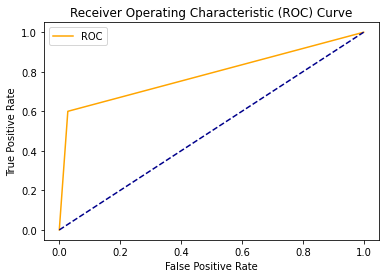

[0.         0.02803738 1.        ]


In [ ]:
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy_percentage = 100 * accuracy
print('accuracy: ',accuracy_percentage)                          #accuracy

tn, fp, fn, tp = cm(y_test, y_pred).ravel()
print('confusion matrix: ',tn, fp, fn, tp)                               #confusion matrix

print('auc roc score: ',aucroc(y_test, z.predict_proba(x_test)[:, 1]))      #auc roc score
print('auc roc score: ',aucroc(y_test, z.decision_function(x_test)))

print('f1 score: ',f1(y_test, y_pred, average='macro'))                     #f1 score
def plot_roc_curve(fpr, tpr):
    plt.plot(fpr, tpr, color='orange', label='ROC')
    plt.plot([0, 1], [0, 1], color='darkblue', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend()
    plt.show()
fpr, tpr, thresholds = rocc(y_test, y_pred)                                 #roc curve
plot_roc_curve(fpr, tpr)
print(fpr)


In [ ]:
!pip install ffmpeg-python

In [ ]:
from IPython.display import Javascript
from google.colab import output
from base64 import b64decode
RECORD = """
const sleep  = time => new Promise(resolve => setTimeout(resolve, time))
const b2text = blob => new Promise(resolve => {
  const reader = new FileReader()
  reader.onloadend = e => resolve(e.srcElement.result)
  reader.readAsDataURL(blob)
})
var record = time => new Promise(async resolve => {
  stream = await navigator.mediaDevices.getUserMedia({ audio: true })
  recorder = new MediaRecorder(stream)
  chunks = []
  recorder.ondataavailable = e => chunks.push(e.data)
  recorder.start()
  await sleep(time)
  recorder.onstop = async ()=>{
    blob = new Blob(chunks)
    text = await b2text(blob)
    resolve(text)
  }
  recorder.stop()
})
"""

In [ ]:
while(True):                                                    #infinite loop to run code and tell prediction after listening 5 sec audio
        #------------------------------------------------------------------------------------------------------------------------------------------------
        def record(sec=5):                                      #recording 5 second audio
          display(Javascript(RECORD))
          s = output.eval_js('record(%d)' % (sec*1000))
          b = b64decode(s.split(',')[1])
          with open('audio.mp3','wb') as f:
            f.write(b)
          return 'audio.mp3'  # or webm ?
        record()
        #------------------------------------------------------------------------------------------------------------------------------------------------
        audio1 = AudioSegment.from_file("audio.mp3")
        louderaudio=audio1*2                                      #making the recorded audio louder
        louderaudio.export("louderaudio.mp3", format='mp3')
        #------------------------------------------------------------------------------------------------------------------------------------------------
        y, sr = librosa.load('louderaudio.mp3', mono=True, duration=5)
        rmse1 = librosa.feature.rms(y=y)
        chroma_stft1 = librosa.feature.chroma_stft(y=y, sr=sr)
        spec_cent1 = librosa.feature.spectral_centroid(y=y, sr=sr)
        spec_bw1 = librosa.feature.spectral_bandwidth(y=y, sr=sr)
        rolloff1 = librosa.feature.spectral_rolloff(y=y, sr=sr)
        zcr1 = librosa.feature.zero_crossing_rate(y)
        mfcc1 = librosa.feature.mfcc(y=y, sr=sr)
        to_append = f'{np.mean(chroma_stft1)} {np.mean(rmse1)} {np.mean(spec_cent1)} {np.mean(spec_bw1)} {np.mean(rolloff1)} {np.mean(zcr1)}'
        for e in mfcc1:
            to_append += f' {np.mean(e)}'
        to_append=to_append.split()
        to_append1=to_append
        file = open('predict.csv', 'a', newline='')
        with file:
            writer = csv.writer(file)
            writer.writerow(to_append)                           #extracting features from recorded audio
            writer.writerow(to_append1)                          #and writing them to a csv file
        #------------------------------------------------------------------------------------------------------------------------------------------------
        df1 = pd.read_csv('predict.csv')
        x_test1=df1                                              #reading the csv file and predicting whether
        y_pred1 = logistic_regression.predict(x_test1)           #baby crying or not
        #------------------------------------------------------------------------------------------------------------------------------------------------
        print(y_pred1)
        if (y_pred1==1):                                         #printing baby condition from prediction
            print('crying!')
        else:
            print ('normal')

        #------------------------------------------------------------------------------------------------------------------------------------------------
        !rm predict.csv
        !rm audio.mp3                                            #deleting the recorded audio and csv file
        !rm louderaudio.mp3
        #------------------------------------------------------------------------------------------------------------------------------------------------
        if (y_pred1==1):                                        #y_pred1 value is in array but we need it in number form
            y_pred2=1
        else:
            y_pred2=0
        #-----------------------------------------------------------------------------------------------------------------------------------------------
        result=firebase.put('/BabyCondition','BabyCrying',y_pred2)  #sending data to firebase
        print(result)
        print('\n')


<IPython.core.display.Javascript object>

[0]
normal
0




<IPython.core.display.Javascript object>

[0]
normal
0




<IPython.core.display.Javascript object>

[0]
normal
0




<IPython.core.display.Javascript object>

[0]
normal
0




<IPython.core.display.Javascript object>

KeyboardInterrupt: ignored